# Практическая работа №5. Классификатор и анализ метрик

**Уровень B.** Датасет IBM Telco Customer Churn.

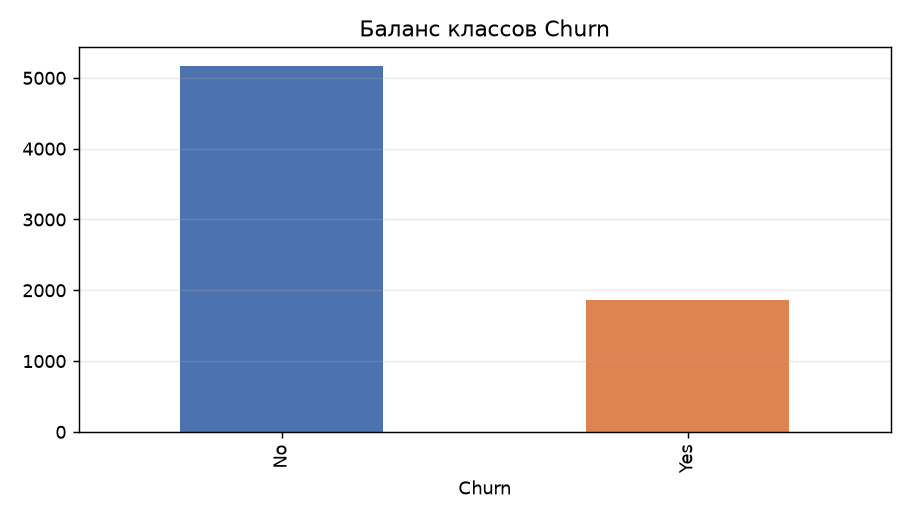

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
df=pd.read_csv("data/Telco-Customer-Churn.csv")
df["TotalCharges"]=pd.to_numeric(df["TotalCharges"],errors="coerce")
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report,ConfusionMatrixDisplay,roc_auc_score
X=df.drop(columns="Churn"); y=df.Churn.map({"Yes":1,"No":0}); num=X.select_dtypes(include=np.number).columns; cat=X.select_dtypes(exclude=np.number).columns; pre=ColumnTransformer([("n",make_pipeline(SimpleImputer(strategy="median"),StandardScaler()),num),("c",make_pipeline(SimpleImputer(strategy="most_frequent"),OneHotEncoder(handle_unknown="ignore")),cat)]); a,b,c,d=train_test_split(X,y,test_size=.2,stratify=y,random_state=42); m=make_pipeline(pre,LogisticRegression(max_iter=1200)).fit(a,c); p=m.predict(b); print(classification_report(d,p)); print("ROC-AUC",roc_auc_score(d,m.predict_proba(b)[:,1])); ConfusionMatrixDisplay.from_predictions(d,p); plt.show()

### Вывод

Результаты представлены таблицами и графиками выше. Обработка данных выполняется воспроизводимо с фиксированным `random_state=42`.